## 1. ABRIENDO DATASET ORIGINAL

"""features que podemos volar
- isbn: podemos eliminar? o nos sirve para el mini recomendador
- text_reviews count: ok
- series: transformar a is_standalone -> booleano
- country_code: hacer one hot encoding sobre si esta en US o no
- language_code: 
- popular_shelves: 
- asin: volar 
- is_ebook: graficar y ver si esto tiene impacto o no
- average_rating: target
- kindle_asin: volar
- similar_books: es hacer trampa?
- description: ver como tratarla
- format: transformarlo con one hot encoding
- publication_month: volar
- publication_year: lo dejamos asi
- url: no se si nos sirve, tal vez para despues. diria que volar
- image_url: volar
- book_id: ni idea
- ratings count: dejar asi
- work id: volar
- titulo: nos lo quedamos asi pero no lo usamos para el entrenamiento
- title_without_series: volar, nos quedamos solo con el titulo
- authors: es un diccionario: como lo tratamos
- publisher: transformar a bool de si tiene publisher o no?
- num_pages: nos lo quedamos asi
- publication_day: volar
- isbn13: volar


In [1]:
import pandas as pd

#tardo 12 segundos en cargar esto
df = pd.read_json(
    "goodreads_books.json",
    lines=True,
    nrows=100000
)

### 1.1 Chusmeando un poco

In [2]:
df.info()
df.head()
df[["average_rating","ratings_count","text_reviews_count"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 29 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   isbn                  100000 non-null  object
 1   text_reviews_count    100000 non-null  object
 2   series                100000 non-null  object
 3   country_code          100000 non-null  object
 4   language_code         100000 non-null  object
 5   popular_shelves       100000 non-null  object
 6   asin                  100000 non-null  object
 7   is_ebook              100000 non-null  object
 8   average_rating        100000 non-null  object
 9   kindle_asin           100000 non-null  object
 10  similar_books         100000 non-null  object
 11  description           100000 non-null  object
 12  format                100000 non-null  object
 13  link                  100000 non-null  object
 14  authors               100000 non-null  object
 15  publisher         

,average_rating,ratings_count,text_reviews_count
count,100000,100000,100000
unique,319,3762,1069
top,4.00,1,1
freq,4699,6919,24588


In [3]:
df[["country_code","language_code","format"]].describe()

,country_code,language_code,format
count,100000,100000,100000
unique,2,96,262
top,US,,Paperback
freq,99982,44885,37669


### 1.2 Otra forma de abrirlo (aleatorio)

In [ ]:
import json
import random
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_books.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)

print(df.shape)
print(df.head())

(100000, 29)
         isbn text_reviews_count    series country_code language_code  \
0  0691009740                 15        []           US                 
1                              1        []           US                 
2                              1  [294941]           US                 
3                             29  [964464]           US           eng   
4  0345410564                 10        []           US                 

                                     popular_shelves        asin is_ebook  \
0  [{'count': '113', 'name': 'to-read'}, {'count'...                false   
1  [{'count': '141', 'name': 'to-read'}, {'count'...                false   
2  [{'count': '409', 'name': 'to-read'}, {'count'...  B00RW6L5X6     true   
3  [{'count': '545', 'name': 'to-read'}, {'count'...                 true   
4  [{'count': '131', 'name': 'to-read'}, {'count'...                false   

  average_rating kindle_asin  ... publication_month edition_information  \
0         

In [5]:
df[["country_code","language_code","format", "edition_information"]].describe()

,country_code,language_code,format,edition_information
count,100000,100000,100000,100000
unique,2,98,267,3735
top,US,,Paperback,
freq,99981,44845,37676,90680


### 1.3 LANGUAGES:

In [6]:
language_code_uniques = df["language_code"].unique()
print(language_code_uniques)

['' 'eng' 'per' 'tur' 'por' 'nl' 'en-GB' 'en-US' 'fil' 'spa' 'rus' 'est'
 'msa' 'ara' 'swe' 'ind' 'ita' 'kor' 'fre' 'isl' 'hun' 'zho' 'gre' 'dan'
 'ger' 'hin' 'pol' 'fin' 'nor' 'en-CA' 'cze' 'slv' 'ben' 'tha' 'scr' 'srp'
 'lit' 'bul' 'pes' 'cat' 'tel' 'jpn' 'rum' 'slo' 'tam' 'vie' 'wel' 'afr'
 'hye' 'sco' 'kat' 'mon' 'lat' 'urd' 'mul' 'mkd' 'sin' 'nno' 'lav' 'ukr'
 'en' 'mal' 'heb' 'gla' 'sqi' 'pt-BR' 'mya' 'kur' 'nep' 'grc' 'sun' 'crh'
 'nob' 'bos' 'mar' 'tgl' 'jav' 'kan' 'mlt' 'tut' 'eus' 'aze' 'guj' 'fao'
 'dut' 'glg' 'tlh' 'gem' 'enm' 'dum' 'bel' '--' 'sux' 'arg' 'nld' 'ang'
 'ota' 'swa']


##### 1.3.a Empty language - con todas

In [7]:
empty_lang = df[df["language_code"] == ""]
print(empty_lang.shape)
print(empty_lang.head())

(44845, 29)
         isbn text_reviews_count    series country_code language_code  \
0  0691009740                 15        []           US                 
1                              1        []           US                 
2                              1  [294941]           US                 
4  0345410564                 10        []           US                 
5  1565643518                  2        []           US                 

                                     popular_shelves        asin is_ebook  \
0  [{'count': '113', 'name': 'to-read'}, {'count'...                false   
1  [{'count': '141', 'name': 'to-read'}, {'count'...                false   
2  [{'count': '409', 'name': 'to-read'}, {'count'...  B00RW6L5X6     true   
4  [{'count': '131', 'name': 'to-read'}, {'count'...                false   
5  [{'count': '5', 'name': 'to-read'}, {'count': ...                false   

  average_rating kindle_asin  ... publication_month edition_information  \
0          

country_code
US    44826
         19
Name: count, dtype: int64


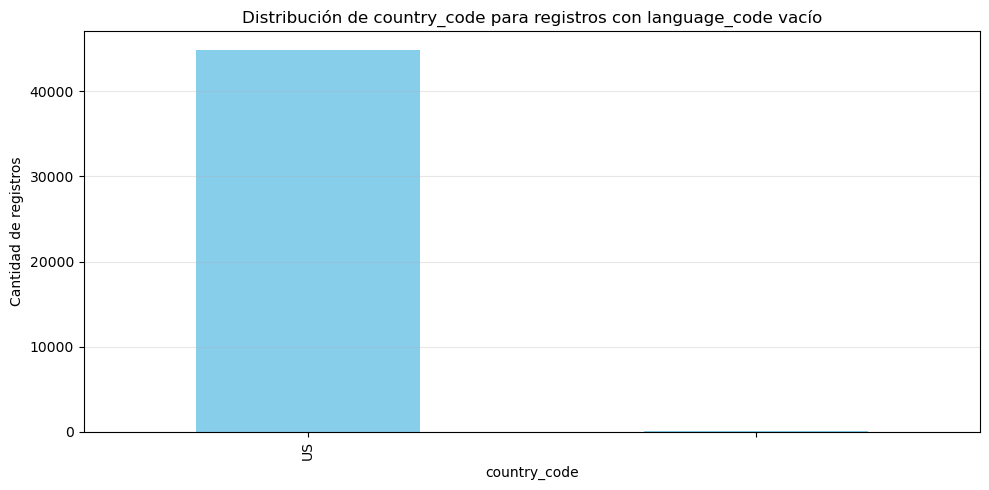

In [8]:
import matplotlib.pyplot as plt

country_counts = empty_lang["country_code"].fillna("<missing>").value_counts()
print(country_counts)

ax = country_counts.plot(
    kind="bar",
    figsize=(10, 5),
    color="skyblue",
    title="Distribución de country_code para registros con language_code vacío"
)
ax.set_xlabel("country_code")
ax.set_ylabel("Cantidad de registros")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
import json

path = "goodreads_books.json"

empty_country_count = 0
with open(path, encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue
        obj = json.loads(line)
        if obj.get("country_code", "") == "":
            empty_country_count += 1

print("Filas con country_code vacío:", empty_country_count)

Filas con country_code vacío: 490


In [12]:
import json

path = "goodreads_books.json"

country_us_count = 0
with open(path, encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue
        obj = json.loads(line)
        if obj.get("country_code") == "US":
            country_us_count += 1

print("Filas con country_code US:", country_us_count)

Filas con country_code US: 2360165


In [13]:
format_uniques = df["format"].unique()
print(format_uniques)

['Kindle Edition' 'Paperback' 'ebook' 'Hardcover' '' 'Audio CD'
 'Unknown Binding' 'Audio' 'Audiobook' 'Softcover' 'Audible Audio'
 'MP3 CD' 'Mass Market Paperback' 'Leather Bound'
 'short story, electronic format' 'Album' 'Library Binding' 'Spiral-bound'
 'paperbound' 'Board book' 'Audio Cassette' 'Hardback' 'paperback'
 'Chapbook' 'Poche' 'Wattpad' 'Paper back' 'Tapa flexible sin solapas'
 'Trade Paperback' 'Comic' 'Board Book' 'paper' 'ebook, CD audio'
 'Unbound' 'Nook' 'Soft Copy' 'Hard Cover' 'softcover' 'ARC' 'Broche'
 'online fiction' 'online fanfiction' "artist's book"
 'Hardcover first edition' 'soft cover' 'Novelty Book' 'hardcover'
 'Free Online Read' 'Online Fiction' 'Klappenbroschur' 'Loose-Leaf'
 'Novel' 'Paperback with flaps' 'stapled' 'Hardcover Comic'
 'Perfect Paperback' 'Wen Ku' 'Audiobook, Audible Download' 'Sarcasm'
 'Online Fiction - Complete' 'sofcover' 'Paperback+DvD' 'Capa mole'
 'Bia mem' 'Comic Book' 'Part-In-Omnibus' 'Other Format' 'Boxed Set'
 'print chapbo

### 1.4 Normalización de la columna `format`

In [ ]:
def normalize_format(value):
    if not isinstance(value, str):
        return "UNKNOWN"
    s = value.strip().lower()
    if s == "":
        return "UNKNOWN"

    # Ebook / digital
    ebook_terms = [
        "ebook", "e-book", "kindle", "nook", "ibook", "epub", "pdf",
        "online fiction", "online free", "online read", "online", "digital",
        "e book", "e-book", "ebook and paperback", "ebook, paperback",
        "nook ebook", "e-book .pdf", "e book, paperback", "e-pub", "ebook pdf"
    ]

    # Audio formats
    audio_terms = [
        "audio", "audiobook", "audio cd", "mp3", "cassette", "audible",
        "digital audio", "audio lecture", "audio book", "audiobook, audible",
        "audio cassette", "mp3 audio", "mp3 book"
    ]

    # Hardcover / hardback
    hardcover_terms = [
        "hardcover", "hard cover", "hardback", "hardbound", "slipcased",
        "hardcover first edition", "hardcover comic", "hardcover (large print)",
        "faux leather", "hardcover with slipcase", "hardcover art"
    ]

    # Paperback / softcover
    paperback_terms = [
        "paperback", "softcover", "soft cover", "trade paperback",
        "mass market paperback", "paper back", "paperbound", "pocket paperback",
        "capa mole", "paper", "brochura", "broche", "book", "brochure",
        "brossura", "paperback with dvd", "paperback with flaps",
        "paperback (large print)", "perfect paperback", "paperback manga"
    ]

    # Comic / manga / graphic
    comic_terms = [
        "comic", "graphic novel", "manga", "webcomic", "fancomic", "comic book",
        "digital comic", "comic book", "graphic"
    ]

    s_norm = s.replace("&amp;", "&")

    if any(term in s_norm for term in ebook_terms) and not any(term in s_norm for term in audio_terms):
        return "EBOOK"
    if any(term in s_norm for term in audio_terms):
        return "AUDIO"
    if any(term in s_norm for term in hardcover_terms):
        return "HARDCOVER"
    if any(term in s_norm for term in paperback_terms):
        return "PAPERBACK"
    if any(term in s_norm for term in comic_terms):
        return "COMIC"

    return "OTHER"

# Crear columna agrupada
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

In [ ]:
df["format_group"].value_counts()

In [ ]:
language_code_uniques = df["language_code"].unique()
print(language_code_uniques)

## 2. ME CREO LOS DATASETS US Y NON-US

In [ ]:
# import json
# import random

# input_path = "goodreads_books.json"
# output_path = "goodreads_books_nonUS.json"

# def read_json(path):
#     with open(path, "r", encoding="utf-8") as f:
#         try:
#             data = json.load(f)
#             return data if isinstance(data, list) else [data]
#         except json.JSONDecodeError:
#             f.seek(0)
#             return [json.loads(line) for line in f if line.strip()]

# data = read_json(input_path)
# filtered = [item for item in data if item.get("country_code") != "US"]

# # Guardar todas las entradas no-US
# with open(output_path, "w", encoding="utf-8") as f:
#     json.dump(filtered, f, ensure_ascii=False, indent=2)

# print(f"Registros no-US: {len(filtered)} → guardados en {output_path}")

# # # Si queremos quedarnos con una muestra de hasta 100000 no-US en vez de todas:
# # k = min(100000, len(filtered))
# # sample = random.sample(filtered, k) if k > 0 else []
# # #Guardamos la muestra si queremos
# # with open("goodreads_books_nonUS_sample.json", "w", encoding="utf-8") as f:
# #     json.dump(sample, f, ensure_ascii=False, indent=2)
# # print(f"Muestra no-US guardada: {len(sample)}")

Registros no-US: 490 → guardados en goodreads_books_nonUS.json
